In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score)
from xgboost import XGBRegressor
import warnings
warnings.filterwarnings("ignore")

In [4]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/house_price_20000.csv")

In [12]:
df.head()

,Area_sqft,Bedrooms,Bathrooms,Location,AgeOfHouse,Parking,FurnishingStatus,NearbySchools,DistanceToCity,PropertyType,HousePrice
0,812,1,2,Suburb,18,No,Semi-Furnished,7,24.7,Apartment,5835743
1,3209,6,5,IT Corridor,11,Yes,Furnished,5,33.8,Apartment,27186830
2,2791,5,5,Downtown,1,No,Semi-Furnished,2,3.0,Independent House,27449142
3,2036,3,3,Suburb,16,No,Semi-Furnished,7,16.3,Apartment,14558571
4,2015,4,4,IT Corridor,14,Yes,Unfurnished,2,21.1,Independent House,18076394


In [5]:
df.shape

(20000, 11)

In [7]:
df.columns

Index(['Area_sqft', 'Bedrooms', 'Bathrooms', 'Location', 'AgeOfHouse',
       'Parking', 'FurnishingStatus', 'NearbySchools', 'DistanceToCity',
       'PropertyType', 'HousePrice'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Area_sqft         20000 non-null  int64  
 1   Bedrooms          20000 non-null  int64  
 2   Bathrooms         20000 non-null  int64  
 3   Location          20000 non-null  object 
 4   AgeOfHouse        20000 non-null  int64  
 5   Parking           20000 non-null  object 
 6   FurnishingStatus  20000 non-null  object 
 7   NearbySchools     20000 non-null  int64  
 8   DistanceToCity    20000 non-null  float64
 9   PropertyType      20000 non-null  object 
 10  HousePrice        20000 non-null  int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 1.7+ MB


In [55]:
df["Parking"].value_counts()

Parking
Yes    14311
No      5689
Name: count, dtype: int64

In [56]:
df["PropertyType"].value_counts()

PropertyType
Apartment            12044
Independent House     5943
Villa                 2013
Name: count, dtype: int64

In [57]:
df["FurnishingStatus"].value_counts()

FurnishingStatus
Semi-Furnished    8997
Unfurnished       5971
Furnished         5032
Name: count, dtype: int64

In [9]:
df.isnull().sum()

Area_sqft           0
Bedrooms            0
Bathrooms           0
Location            0
AgeOfHouse          0
Parking             0
FurnishingStatus    0
NearbySchools       0
DistanceToCity      0
PropertyType        0
HousePrice          0
dtype: int64

In [10]:
df.describe()

,Area_sqft,Bedrooms,Bathrooms,AgeOfHouse,NearbySchools,DistanceToCity,HousePrice
count,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,2.000000e+04
mean,2237.722150,3.464500,3.142550,19.96200,3.497900,18.096120,1.719977e+07
std,1008.999948,1.639535,1.480351,11.81031,2.278125,9.855136,9.081516e+06
min,500.000000,1.000000,1.000000,0.00000,0.000000,1.000000,8.000000e+05
25%,1365.750000,2.000000,2.000000,10.00000,2.000000,9.500000,9.514130e+06
50%,2236.000000,3.000000,3.000000,20.00000,3.000000,18.100000,1.594182e+07
75%,3107.000000,5.000000,5.000000,30.00000,5.000000,26.700000,2.446968e+07
max,4000.000000,6.000000,5.000000,40.00000,7.000000,35.000000,4.036174e+07


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Area_sqft         20000 non-null  int64  
 1   Bedrooms          20000 non-null  int64  
 2   Bathrooms         20000 non-null  int64  
 3   Location          20000 non-null  object 
 4   AgeOfHouse        20000 non-null  int64  
 5   Parking           20000 non-null  object 
 6   FurnishingStatus  20000 non-null  object 
 7   NearbySchools     20000 non-null  int64  
 8   DistanceToCity    20000 non-null  float64
 9   PropertyType      20000 non-null  object 
 10  HousePrice        20000 non-null  int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 1.7+ MB


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
X=df.drop(columns="HousePrice",axis=1)
y=df["HousePrice"]

In [18]:
numerical_cal=X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_cal=X.select_dtypes(include=["object"]).columns.tolist()

In [38]:
numerical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="median")),
    ("scler",StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])


In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print(X_train.shape)
print(X_test.shape)
print(y_trian.shape)
print(y_test.shape)

Training Data: (16000, 10)
Testing Data: (4000, 10)
(16000, 10)
(4000, 10)
(16000,)
(4000,)


In [40]:
preprocessing=ColumnTransformer(transformers=[
    ("num",numerical_transformer,numerical_cal),
    ("cat",categorical_transformer,categorical_cal)
])

In [41]:
model = Pipeline(steps=[
    ("preprocessing",preprocessing),
    ("regressor", XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ))])
model.fit(X_train,y_trian)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Area_sqft','Bedrooms','Bathrooms',...,'NearbySchools','DistanceToCity', 'PropertyType']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through.

In [42]:
y_pred=model.predict(X_test)

In [43]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE : 465135.72
MSE : 339341869056.0
RMSE: 582530.57
R2 Score: 0.9958


# Actual vs Predicted visualization

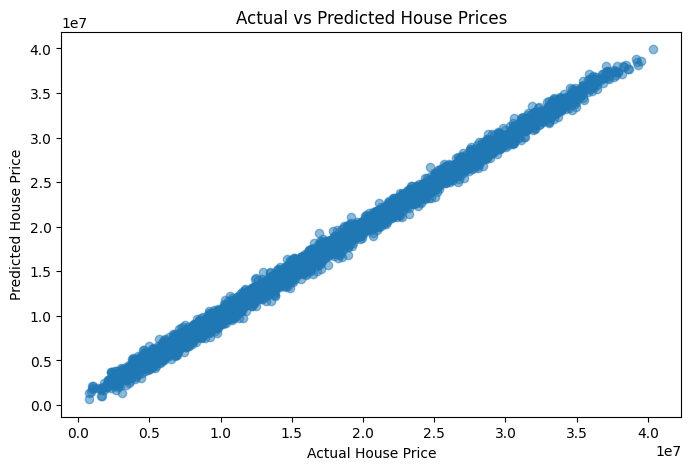

In [44]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

# Hyperparameter tuning using RandomizedSearchCV

In [47]:
param_grid = {
    "regressor__n_estimators": [100, 200, 300, 400],
    "regressor__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__max_depth": [3, 4, 5, 6, 8],
    "regressor__min_child_weight": [1, 3, 5],
    "regressor__subsample": [0.7, 0.8, 0.9, 1.0],
    "regressor__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__colsample_bytree': [0.7, 0.8, ...], 'regressor__learning_rate': [0.01, 0.03, ...], 'regressor__max_depth': [3, 4, ...], 'regressor__min_child_weight': [1, 3, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimat

In [48]:
print("Best Parameters:", random_search.best_params_)
print("Best CV R2 Score:", random_search.best_score_)

Best Parameters: {'regressor__subsample': 0.7, 'regressor__n_estimators': 400, 'regressor__min_child_weight': 5, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 0.7}
Best CV R2 Score: 0.9956358869870504


# Evaluate tuned model

In [53]:
best_model = random_search.best_estimator_
tuned_predictions = best_model.predict(X_test)
print("Tuned MAE:", mean_absolute_error(y_test, tuned_predictions))
print("Tuned RMSE:", np.sqrt(mean_squared_error(y_test, tuned_predictions)))
print("Tuned R2:", r2_score(y_test, tuned_predictions))

Tuned MAE: 466937.75
Tuned RMSE: 584853.0247916993
Tuned R2: 0.9958130717277527
